In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))

import joblib
import shap
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from src.preprocessing import get_preprocessor
import lime
import lime.lime_tabular
import numpy as np

c:\ai&machin\final_ml _project\telco-churn-mlops\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\ai&machin\final_ml _project\telco-churn-mlops\src\preprocessing.py:15: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas

In [2]:
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.drop('customerID', axis=1, inplace=True)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')


X = df.drop('Churn', axis=1)
encoder_target = LabelEncoder()
y = encoder_target.fit_transform(df['Churn'])


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



C:\Users\roky\AppData\Local\Temp\ipykernel_17800\1169100114.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('customerID', axis=1, inplace=True)


In [3]:
xgb_pipeline = joblib.load('../models/xgboost_pipeline.joblib')

In [4]:
preprocessor = xgb_pipeline.named_steps['preprocessor']
xgb_model = xgb_pipeline.named_steps['classifier']

In [5]:
X_test_transformed = preprocessor.transform(X_test)
feature_names = [
    name.split('__')[-1] 
    for name in preprocessor.get_feature_names_out()
]

In [6]:
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [7]:
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_df)

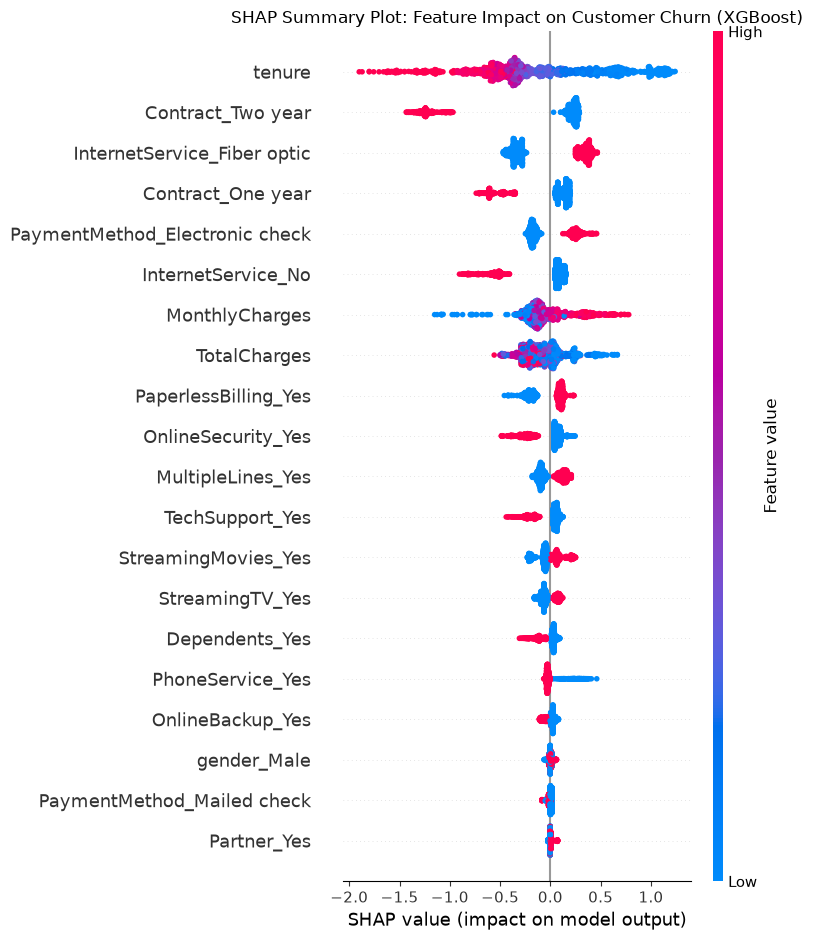

In [8]:
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_test_df, show=False)
plt.title("SHAP Summary Plot: Feature Impact on Customer Churn (XGBoost)")
plt.tight_layout()
plt.show()

In [9]:
X_train_transformed = preprocessor.transform(X_train)

In [10]:
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_transformed,
    feature_names=feature_names,
    class_names=['No Churn (0)', 'Churn (1)'],
    mode='classification',
    random_state=42
)

In [11]:
sample_idx = 0  
customer_instance = X_test_transformed[sample_idx]

In [12]:
exp = lime_explainer.explain_instance(
    data_row=customer_instance,
    predict_fn=xgb_model.predict_proba,
    num_features=10
)

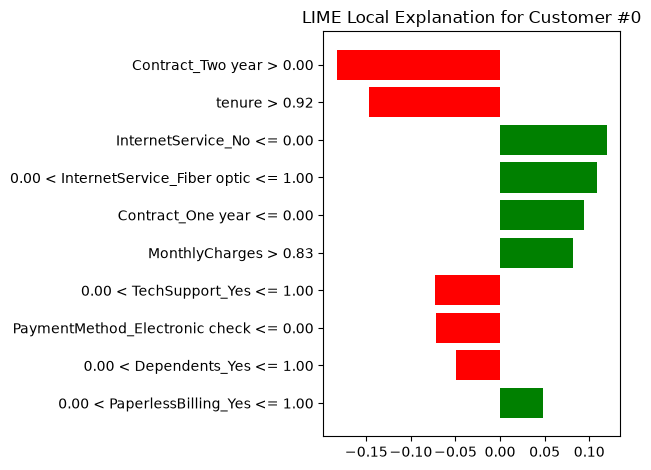

In [13]:
fig = exp.as_pyplot_figure()
plt.title(f"LIME Local Explanation for Customer #{sample_idx}")
plt.tight_layout()
plt.show()